## scMAVERICS - snATACseq processing

**🚨 HALT! 🚨**

This section assumes you have completed the previous section, [snRNAseq preprocessing](snRNAseq.md), with the object `06_QC_filtered_anndata_rna.h5ad` in the `atlas` folder. If not, go back and complete the analysis, preferably with the Snakemake pipeline.

This analysis is less standard than the previous page, and subsequently this analysis 

This notebook and all others, can be created from the instructions [here](https://github.com/NIH-CARD/scMAVERICS/tree/main#local-environment)

## Package and data loading

In [ ]:
import anndata as ad
import pandas as pd
import scanpy as sc
import snapatac2 as snap
import scipy

import numpy as np
import polars as pl
import pyranges as pr
import os

### Define working and data directories

In [2]:
data_dir = '/data/CARD_singlecell/Brain_atlas/SN_Multiome/'
work_dir = '/data/CARD_singlecell/SN_atlas/' 

### Load metadata

As stated before, metadata should be imported, for visualizing parameters, 

In [3]:
metadata_df = pd.read_csv(work_dir + 'input/metadata.csv')
metadata_df

,Sample_ID,Use_batch,Age,PMI,Sex,Brain_bank,Primary Diagnosis
0,6178,6,68,22.5,Male,Human Brain and Spinal Fluid Resource Center,control
1,3284,1,78,11.5,Female,Human Brain and Spinal Fluid Resource Center,control
2,6384,3,50,22.3,Female,Human Brain and Spinal Fluid Resource Center,PD
3,5638,3,77,19.3,Male,Human Brain and Spinal Fluid Resource Center,PD


In [15]:
# Define keys
sample_key = 'Sample_ID'
batch_key = 'Use_batch'

# Define list of samples
samples = metadata_df[sample_key].astype(str)
batches = metadata_df[batch_key]
# Ensure sample names are strings
metadata_df[sample_key] = metadata_df[sample_key].astype(str)

In [5]:
step_1_files = [data_dir + f'/batch{batches[i]}/Multiome/{samples[i]}-ARC/outs/02_{samples[i]}_anndata_atac.h5ad' for i in range(len(samples))]
step_1_files

['/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch6/Multiome/6178-ARC/outs/02_6178_anndata_atac.h5ad',
 '/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch1/Multiome/3284-ARC/outs/02_3284_anndata_atac.h5ad',
 '/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch3/Multiome/6384-ARC/outs/02_6384_anndata_atac.h5ad',
 '/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch3/Multiome/5638-ARC/outs/02_5638_anndata_atac.h5ad']

In [6]:
# Read in anndata objects using backed mode
data_dir+'{batch}/Multiome/{sample}/outs/atac_fragments.tsv.gz'
fragments = [data_dir + f'/batch{batches[i]}/Multiome/{samples[i]}-ARC/outs/atac_fragments.tsv.gz' for i in range(len(samples))]
fragments

['/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch6/Multiome/6178-ARC/outs/atac_fragments.tsv.gz',
 '/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch1/Multiome/3284-ARC/outs/atac_fragments.tsv.gz',
 '/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch3/Multiome/6384-ARC/outs/atac_fragments.tsv.gz',
 '/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch3/Multiome/5638-ARC/outs/atac_fragments.tsv.gz']

## atac_merge

In [7]:
adatas = snap.pp.import_fragments(
        fragments, 
        file=step_1_files, 
        chrom_sizes=snap.genome.hg38.chrom_sizes,
        sorted_by_barcode=False,
        min_num_fragments=1000,
        )
adatas

100%|██████████| 4/4 [03:34<00:00, 53.52s/it] 


[AnnData object with n_obs x n_vars = 10502 x 0 backed at '/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch6/Multiome/6178-ARC/outs/02_6178_anndata_atac.h5ad'
     obs: 'n_fragment', 'frac_dup', 'frac_mito'
     uns: 'reference_sequences'
     obsm: 'fragment_paired',
 AnnData object with n_obs x n_vars = 9891 x 0 backed at '/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch1/Multiome/3284-ARC/outs/02_3284_anndata_atac.h5ad'
     obs: 'n_fragment', 'frac_dup', 'frac_mito'
     uns: 'reference_sequences'
     obsm: 'fragment_paired',
 AnnData object with n_obs x n_vars = 8346 x 0 backed at '/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch3/Multiome/6384-ARC/outs/02_6384_anndata_atac.h5ad'
     obs: 'n_fragment', 'frac_dup', 'frac_mito'
     uns: 'reference_sequences'
     obsm: 'fragment_paired',
 AnnData object with n_obs x n_vars = 7710 x 0 backed at '/data/CARD_singlecell/Brain_atlas/SN_Multiome//batch3/Multiome/5638-ARC/outs/02_5638_anndata_atac.h5ad'
     obs: 'n_fragment

In [8]:
# Transcription start site filter
snap.metrics.tsse(adatas, snap.genome.hg38)
# Minimum number of fragments filter
snap.pp.filter_cells(adatas, min_tsse=2.5)


100%|██████████| 4/4 [00:17<00:00,  4.31s/it]


In [16]:
adataset = snap.AnnDataSet(
    adatas = [(samples[i], adatas[i]) for i in (range(len(adatas)))],
    filename = work_dir+'atlas/temp_atac_delete_later.h5ad'
)
adataset

AnnDataSet object with n_obs x n_vars = 34934 x 0 backed at '/data/CARD_singlecell/SN_atlas/atlas/temp_atac_delete_later.h5ad'
contains 4 AnnData objects
    obs: 'sample'
    uns: 'reference_sequences', 'AnnDataSet'

In [17]:
adataset.obs_names = np.array(adataset.obs_names) + '_' + np.array(adataset.obs['sample'])
adataset.obs['n_fragment'] = adataset.adatas.obs['n_fragment']
adataset.obs['tsse'] = adataset.adatas.obs['tsse']

In [18]:
adataset

AnnDataSet object with n_obs x n_vars = 34934 x 0 backed at '/data/CARD_singlecell/SN_atlas/atlas/temp_atac_delete_later.h5ad'
contains 4 AnnData objects
    obs: 'sample', 'n_fragment', 'tsse'
    uns: 'reference_sequences', 'AnnDataSet'

## atac_fragment_pseudobulk

In [ ]:
# Define the peak bed files
celltype_fragment_files = [ for celltype in cell_df.celltype.drop_duplicates()]
celltype_fragment_files

['/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_fragments.bed',
 '/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/OPC/OPC_fragments.bed',
 '/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/DaN/DaN_fragments.bed',
 '/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/Astro/Astro_fragments.bed',
 '/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/ExN/ExN_fragments.bed',
 '/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/Oligo/Oligo_fragments.bed',
 '/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/InN/InN_fragments.bed',
 '/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/PC/PC_fragments.bed',
 '/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/MG/MG_fragments.bed',
 '/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/TC/TC_fragments.bed']

In [19]:
rna = sc.read_h5ad(work_dir + '/atlas/06_QC_filtered_anndata_rna.h5ad')

In [ ]:
# Port cell data from final RNA atlas to cisTopic pseudobulked
cell_df = rna.obs

# Extract the cell barcode column
if 'cell_barcode' not in cell_df.columns:
    cell_df['cell_barcode'] = [x.split('-1_')[0] + '-1' for x in cell_df.index]

In [44]:
# Iterate over the cell types
for j, celltype in enumerate(cell_df.celltype.drop_duplicates()):
    # For sample in samples
    for i, sample in enumerate(samples):
        # Define fragment file
        bed_location = fragments[i]
        # Load fragment with polars
        print(f'Loading sample {sample} fragments')
        pl_fragment = pl.read_csv(bed_location, separator='\t', comment_prefix='#', n_threads=8)

        # To make sure the same columns are being read in
        num_blank = len(pl_fragment.columns) - 5
        pl_fragment.columns = ['chrom', 'chromStart', 'chromEnd', 'name', 'score'] + ['.']*num_blank
        pl_fragment.columns = ['chrom', 'chromStart', 'chromEnd', 'name', 'score'] + ['.']*num_blank
        pl_fragment = pl_fragment[['chrom', 'chromStart', 'chromEnd', 'name', 'score']]
        
        # Get list of sample and cell type specific barcodes
        cell_type_barcodes = cell_df[(cell_df['celltype']== celltype) & (cell_df[sample_key] == sample)]['cell_barcode'].to_list()
        # Filter on the cell type barcodes
        cell_fragment = pl_fragment.filter(pl_fragment['name'].is_in(cell_type_barcodes))

        # 
        celltype_fragment_file = work_dir + f'data/temp_celltype_fragment/{celltype}/{celltype}_fragments.bed'

        # Create fragment 

        # Add the filtered barcodes to the fragments
        print(f'Writing sample {celltype_fragment_file}')

        if not os.path.exists(celltype_fragment_file):
            os.makedirs('/'.join(celltype_fragment_file.split('/')[:-1]))
            with open(celltype_fragment_file, 'w') as f:
                cell_fragment.write_csv(f, include_header=False, separator='\t')
                f.close()
        else:
            with open(celltype_fragment_file, 'a+') as f:
                cell_fragment.write_csv(f, include_header=False, separator='\t')
                f.close()

Loading sample 6178 fragments
Writing sample /data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_fragments.bed
Loading sample 3284 fragments
Writing sample /data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_fragments.bed
Loading sample 6384 fragments
Writing sample /data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_fragments.bed
Loading sample 5638 fragments
Writing sample /data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_fragments.bed
Loading sample 6178 fragments
Writing sample /data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/OPC/OPC_fragments.bed
Loading sample 3284 fragments
Writing sample /data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/OPC/OPC_fragments.bed
Loading sample 6384 fragments
Writing sample /data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/OPC/OPC_fragments.bed
Loading sample 5638 fragments
Writing sample /data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/OPC/OPC_fragments.bed


## atac_celltype_call_peaks

```
macs3 callpeak \
--treatment /data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_fragments.bed \
--name EC \
--outdir data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/ \
--format BEDPE --gsize hs --qvalue 0.001 --nomodel --shift 73 --extsize 146 --keep-dup all
```

```
INFO  @ 02 Nov 2026 13:09:34: [34 MB] 
# Command line: callpeak --treatment /data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_fragments.bed --name EC --outdir data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC --format BEDPE --gsize hs --qvalue 0.001 --nomodel --shift 73 --extsize 146 --keep-dup all
# ARGUMENTS LIST:
# name = EC
# format = BEDPE
# ChIP-seq file = ['/data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_fragments.bed']
# control file = None
# effective genome size = 2.91e+09
# band width = 300
# model fold = [5, 50]
# qvalue cutoff = 1.00e-03
# The maximum gap between significant sites is assigned as the read length/tag size.
# The minimum length of peaks is assigned as the predicted fragment length "d".
# Larger dataset will be scaled towards smaller dataset.
# Range for calculating regional lambda is: 10000 bps
# Broad region calling is off
# Paired-End mode is on
 
INFO  @ 02 Nov 2026 13:09:34: [34 MB] #1 read fragment files... 
INFO  @ 02 Nov 2026 13:09:34: [34 MB] #1 read treatment fragments... 
INFO  @ 02 Nov 2026 13:09:35: [103 MB]  1000000 fragments parsed 
INFO  @ 02 Nov 2026 13:09:35: [114 MB]  2000000 fragments parsed 
INFO  @ 02 Nov 2026 13:09:36: [145 MB]  3000000 fragments parsed 
INFO  @ 02 Nov 2026 13:09:36: [153 MB]  4000000 fragments parsed 
INFO  @ 02 Nov 2026 13:09:37: [160 MB]  5000000 fragments parsed 
INFO  @ 02 Nov 2026 13:09:38: [160 MB] #1 mean fragment size is determined as 157.4 bp from treatment 
INFO  @ 02 Nov 2026 13:09:38: [160 MB] #1 fragment size = 157.4 
INFO  @ 02 Nov 2026 13:09:38: [160 MB] #1  total fragments in treatment: 5066959 
INFO  @ 02 Nov 2026 13:09:38: [160 MB] #1 finished! 
INFO  @ 02 Nov 2026 13:09:38: [160 MB] #2 Build Peak Model... 
INFO  @ 02 Nov 2026 13:09:38: [160 MB] #2 Skipped... 
INFO  @ 02 Nov 2026 13:09:38: [160 MB] #3 Call peaks... 
INFO  @ 02 Nov 2026 13:09:38: [160 MB] #3 Pre-compute pvalue-qvalue table... 
INFO  @ 02 Nov 2026 13:09:54: [264 MB] #3 Call peaks for each chromosome... 
INFO  @ 02 Nov 2026 13:09:57: [264 MB] #4 Write output xls file... data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_peaks.xls 
INFO  @ 02 Nov 2026 13:09:57: [264 MB] #4 Write peak in narrowPeak format file... data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_peaks.narrowPeak 
INFO  @ 02 Nov 2026 13:09:57: [264 MB] #4 Write summits bed file... data/CARD_singlecell/SN_atlas/data/temp_celltype_fragment/EC/EC_summits.bed 
INFO  @ 02 Nov 2026 13:09:57: [264 MB] Done! 
```

## atac_consensus_peaks

In [ ]:
# Read in narrow peak dictionaries
peak_files = snakemake.input.narrow_peaks

In [ ]:
# Create narrow peak object
narrow_peak_dict = dict(zip(cells, [pyranges.PyRanges(pyranges.read_bed(x).df.rename(columns={'ThickStart': 'FC_summit', 'ThickEnd': '-log10_pval', 'ItemRGB': '-log10_qval', 'BlockCount': 'Summit'}, copy=True)) for x in peak_files]))


In [ ]:
# Read in chromosome lengths
chromsizes = pd.read_table(
    "http://hgdownload.cse.ucsc.edu/goldenPath/hg38/bigZips/hg38.chrom.sizes",
    header = None,
    names = ["Chromosome", "End"]
)
chromsizes.insert(1, "Start", 0)

In [ ]:
# Set peak target width
peak_half_width=250

In [ ]:
# Get consensus peaks from peak dictionary
consensus_peaks = get_consensus_peaks(
    narrow_peaks_dict = narrow_peak_dict,
    peak_half_width = peak_half_width,
    chromsizes = chromsizes)

# Export the consensus bed file
consensus_peaks.to_bed(
    path = snakemake.output.consensus_bed,
    keep =True,
    compression = 'infer',
    chain = False)

## atac_merged_consensus_peak

In [47]:
# Import consensus peak
consensus_bed = work_dir + 'data/consensus_regions.bed'

atac = snap.pp.make_peak_matrix(
        adataset,
        peak_file = consensus_bed
        )

atac

/data/catchingba/.conda/envs/multiome/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


AnnData object with n_obs × n_vars = 34934 × 608977
    obs: 'sample', 'n_fragment', 'tsse'

## atac_spectral

In [48]:
# Select the top N number of features 
snap.pp.select_features(atac, n_features=20000)

2026-11-02 13:58:05 - INFO - Selected 20000 features.


In [49]:
# Spectral multidimensional scaling
snap.tl.spectral(atac, num_threads=32)

In [51]:
# Perform mutual nearest neighbors
snap.pp.mnc_correct(
    atac, 
    batch='sample', 
    key_added='X_spectral',
    n_jobs = 32)

In [52]:
# Compute 
snap.pp.knn(
    atac, 
    use_rep='X_spectral'
    )

In [53]:
# Compute UMAP
snap.tl.umap(
    atac, 
    n_comps=2)

/data/catchingba/.conda/envs/multiome/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


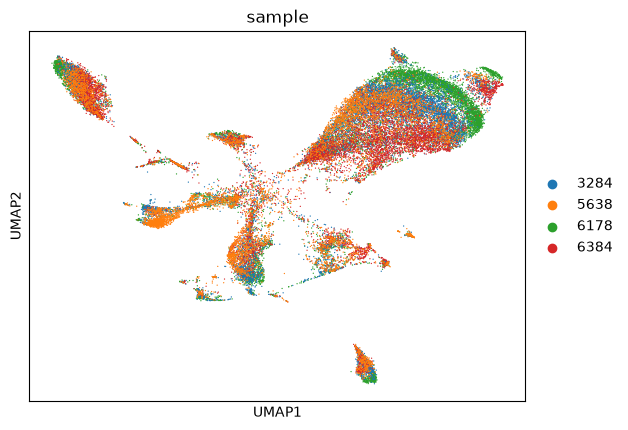

In [56]:
sc.pl.umap(
    atac,
    color = 'sample'
)

In [55]:
atac.write_h5ad(work_dir + '/atlas/04_modeled_anndata_atac.h5ad', compression = 'gzip')

... storing 'sample' as categorical
